# AI Exposure and Occupational Wages
**ECON 326 · U.S. occupations, 2025**

How is occupational AI exposure related to wages, and how does the association change when we account for human skills? Models 1–5 build up the main analysis. Models 6–7 check whether the findings hold with a nonlinear specification or employment weighting. All reported inference uses HC1 robust standard errors. These regressions describe associations across occupations.

## 1. Data preparation
The setup cell names the four inputs for the 2025 analysis. The 2019 workbook and CPI CSV are optional and used only in Section 6.

In [1]:
library(readxl)
suppressPackageStartupMessages(library(dplyr))
library(tidyr)
library(ggplot2)

data_dir <- "Econ326_Data"
main_files <- file.path(data_dir, c(
  "national_M2025_dl.xlsx",
  "AIOE_DataAppendix (2).xlsx",
  "db_27_0_excel/Skills.xlsx",
  "2010_to_2019_Crosswalk (2).xlsx"
))
missing_files <- main_files[!file.exists(main_files)]
if (length(missing_files)) {
  stop("Missing 2025 inputs: ", paste(missing_files, collapse = ", "))
}

bls_raw <- read_excel(main_files[1])
ai_raw <- read_excel(main_files[2], sheet = "Appendix A")
skills_raw <- read_excel(main_files[3])
crosswalk_raw <- read_excel(main_files[4], skip = 3)

### Select detailed national BLS records

In [2]:
bls_selected <- bls_raw %>%
  filter(AREA == "99",
    NAICS == "000000",
    OWN_CODE == "1235",
    O_GROUP == "detailed") %>%
  select(soc = OCC_CODE,occupation = OCC_TITLE,
    wage = A_MEAN,
    employment = TOT_EMP)
nrow(bls_selected)

[1] 830

In [3]:
bls_selected %>%
  filter(is.na(suppressWarnings(as.numeric(wage)))) %>%
  select(soc, occupation, wage)

soc,occupation,wage
<chr>,<chr>,<chr>
27-2011,Actors,*
27-2031,Dancers,*
27-2042,Musicians and Singers,*
27-2091,"Disc Jockeys, Except Radio",*
27-2099,"Entertainers and Performers, Sports and Related Workers, All Other",*


In [4]:
bls <- bls_selected %>%
  mutate(wage = suppressWarnings(as.numeric(wage)),
    employment = suppressWarnings(as.numeric(employment)))
head(bls)

soc,occupation,wage,employment
<chr>,<chr>,<dbl>,<dbl>
11-1011,Chief Executives,269630,204350
11-1021,General and Operations Managers,134940,3503020
11-2011,Advertising and Promotions Managers,154280,21470
11-2021,Marketing Managers,177770,395240
11-2022,Sales Managers,164350,637080
11-2032,Public Relations Managers,164760,74850


### Match AI exposure using the SOC crosswalk

In [5]:
ai <- ai_raw %>%
  select(soc_2010 = `SOC Code`,
    AI_exposure = AIOE )

head(ai)

soc_2010,AI_exposure
<chr>,<dbl>
11-1011,1.3342460
11-1021,0.5748773
11-2011,1.2943870
11-2021,1.3150320
11-2022,1.2662800
11-2031,1.2936890


In [6]:
crosswalk <- crosswalk_raw %>%
  select(
    code_2010 = `O*NET-SOC 2010 Code`,
    code_2019 = `O*NET-SOC 2019 Code`)

head(crosswalk)

code_2010,code_2019
<chr>,<chr>
11-1011.00,11-1011.00
11-1011.03,11-1011.03
11-1021.00,11-1021.00
11-1031.00,11-1031.00
11-2011.00,11-2011.00
11-2011.01,11-2011.00


In [7]:
crosswalk <- crosswalk %>%
  mutate(code_2010 = substr(code_2010, 1, 7),
    code_2019 = substr(code_2019, 1, 7))


In [8]:
crosswalk <- distinct(crosswalk)

crosswalk <- crosswalk %>%
  group_by(code_2010) %>%
  mutate(new_matches = n()) %>%
  ungroup()

crosswalk <- crosswalk %>%
  group_by(code_2019) %>%
  mutate(old_matches = n()) %>%
  ungroup()

In [9]:
stable_codes <- crosswalk %>%
  filter(new_matches == 1,
    old_matches == 1,
    code_2010 == code_2019)

bls_stable <- merge(
  bls,
  stable_codes,
  by.x = "soc",
  by.y = "code_2019")

In [10]:
matched_ai <- merge(bls_stable,
  ai,
  by.x = "code_2010",
  by.y = "soc_2010")

matched_ai_usable <- matched_ai %>%
  filter(!is.na(wage), wage > 0,
    !is.na(employment), employment > 0,
    !is.na(AI_exposure))

### Prepare skill ratings and join them to the wage data

In [11]:
skills <- skills_raw %>%
  filter(`Scale ID` == "IM")

skills <- skills %>%
  filter(`Element Name` %in% c(
    "Speaking",
    "Active Listening",
    "Critical Thinking",
    "Complex Problem Solving",
    "Judgment and Decision Making"))

skills <- skills %>%
  select(soc = `O*NET-SOC Code`,
    skill = `Element Name`,
    rating = `Data Value`)

skills$soc <- substr(skills$soc, 1, 7)

skills_average <- skills %>%
  group_by(soc, skill) %>%
  summarise(rating = mean(rating),
    .groups = "drop")
head(skills_average)

soc,skill,rating
<chr>,<chr>,<dbl>
11-1011,Active Listening,4.06
11-1011,Complex Problem Solving,4.19
11-1011,Critical Thinking,4.25
11-1011,Judgment and Decision Making,4.19
11-1011,Speaking,4.19
11-1021,Active Listening,4.00


In [12]:
skills_wide <- skills_average %>%
  pivot_wider(names_from = skill,
    values_from = rating)
head(skills_wide)

soc,Active Listening,Complex Problem Solving,Critical Thinking,Judgment and Decision Making,Speaking
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
11-1011,4.06,4.19,4.25,4.19,4.19
11-1021,4.00,3.50,3.88,3.50,4.00
11-2011,4.12,3.50,4.00,3.75,4.00
11-2021,3.88,3.62,3.88,3.75,3.88
11-2022,4.00,3.75,3.88,3.75,4.00
11-3012,4.00,3.25,3.75,3.25,3.88


In [13]:
matched_skills <- merge(matched_ai_usable,skills_wide,
  by = "soc",
  all.x = TRUE)

analysis_data <- matched_skills %>%
  drop_na( Speaking,
    `Active Listening`,
    `Critical Thinking`,
    `Complex Problem Solving`,
    `Judgment and Decision Making`)

analysis_data %>%
  summarise(N = n(),
    Mean = mean(wage),
    SD = sd(wage),
    Min = min(wage),
    Max = max(wage))

N,Mean,SD,Min,Max
<int>,<dbl>,<dbl>,<dbl>,<dbl>
624,74421.17,37793.98,31980,346490


### Create the log variables and standardized indices

In [14]:
analysis_data <- analysis_data %>%
  mutate(log_wage = log(wage),
    log_employment = log(employment))

analysis_data %>%
  summarise(Mean = mean(log_wage),
    SD = sd(log_wage),
    Min = min(log_wage),
    Max = max(log_wage))

Mean,SD,Min,Max
<dbl>,<dbl>,<dbl>,<dbl>
11.12097,0.4192232,10.37287,12.75561


In [15]:
analysis_data <- analysis_data %>%
  mutate(AI = (AI_exposure - mean(AI_exposure)) / sd(AI_exposure) )

analysis_data %>%
  summarise(Mean = mean(AI),
    SD = sd(AI),
    Min = min(AI),
    Max = max(AI))

Mean,SD,Min,Max
<dbl>,<dbl>,<dbl>,<dbl>
-3.437421e-16,1,-2.032543,1.573079


In [16]:
analysis_data <- analysis_data %>%
  mutate(Speaking_z = (Speaking - mean(Speaking)) / sd(Speaking),
    Listening_z =(`Active Listening` - mean(`Active Listening`)) /sd(`Active Listening`),
    CriticalThinking_z =(`Critical Thinking` - mean(`Critical Thinking`)) /sd(`Critical Thinking`),
    ProblemSolving_z =(`Complex Problem Solving` - mean(`Complex Problem Solving`)) /sd(`Complex Problem Solving`),
    Judgment_z =(`Judgment and Decision Making` -mean(`Judgment and Decision Making`)) /sd(`Judgment and Decision Making`)
)

analysis_data <- analysis_data %>%
  mutate(skills_average = (
      Speaking_z +
      Listening_z +
      CriticalThinking_z +
      ProblemSolving_z +
      Judgment_z) / 5 )

In [17]:
analysis_data <- analysis_data %>%
  mutate(Skills = (skills_average - mean(skills_average)) /
      sd(skills_average) )

analysis_data %>%
  summarise(Mean = mean(Skills),
    SD = sd(Skills),
    Min = min(Skills),
    Max = max(Skills))

Mean,SD,Min,Max
<dbl>,<dbl>,<dbl>,<dbl>
-1.069301e-16,1,-2.714252,2.661249


In [18]:
analysis_data <- analysis_data %>%
  mutate(communication_average =
      (Speaking_z + Listening_z) / 2,

    problem_average =(CriticalThinking_z + ProblemSolving_z + Judgment_z) / 3)

analysis_data <- analysis_data %>%
  mutate(Communication =(communication_average - mean(communication_average)) /sd(communication_average),

    ProblemSolving =
      (problem_average - mean(problem_average)) /
      sd(problem_average)
  )

analysis_data %>%
  summarise(
    Communication_mean = mean(Communication),
    Communication_SD = sd(Communication),
    ProblemSolving_mean = mean(ProblemSolving),
    ProblemSolving_SD = sd(ProblemSolving)
  )

Communication_mean,Communication_SD,ProblemSolving_mean,ProblemSolving_SD
<dbl>,<dbl>,<dbl>,<dbl>
1.492396e-15,1,-3.227475e-16,1


In [19]:
analysis_data %>%
  summarise(
    Mean = mean(ProblemSolving),
    SD = sd(ProblemSolving)
  )

Mean,SD
<dbl>,<dbl>
-3.227475e-16,1


### Create occupation groups, indicators, and squared terms

In [20]:
analysis_data <- analysis_data %>%
  separate(soc,into = c("occupation_group", "occupation_detail"),
    sep = "-", remove = FALSE)

In [21]:
analysis_data <- analysis_data %>%
  mutate(
    AI_squared = AI^2,
    Skills_squared = Skills^2,

    Management = as.numeric(occupation_group == "11"),
    Business = as.numeric(occupation_group == "13"),
    Computer = as.numeric(occupation_group == "15"),
    Engineering = as.numeric(occupation_group == "17"),
    Science = as.numeric(occupation_group == "19"),
    Community = as.numeric(occupation_group == "21"),
    Legal = as.numeric(occupation_group == "23"),
    Education = as.numeric(occupation_group == "25"),
    Arts = as.numeric(occupation_group == "27"),
    Healthcare = as.numeric(occupation_group == "29"),
    Healthcare_support = as.numeric(occupation_group == "31"),
    Protective_service = as.numeric(occupation_group == "33"),
    Food_service = as.numeric(occupation_group == "35"),
    Cleaning = as.numeric(occupation_group == "37"),
    Personal_care = as.numeric(occupation_group == "39"),
    Sales = as.numeric(occupation_group == "41"),
    Office = as.numeric(occupation_group == "43"),
    Farming = as.numeric(occupation_group == "45"),
    Construction = as.numeric(occupation_group == "47"),
    Maintenance = as.numeric(occupation_group == "49"),
    Production = as.numeric(occupation_group == "51"),
    Transportation = as.numeric(occupation_group == "53")
  )

In [22]:
analysis_data$occupation_group <- factor(analysis_data$occupation_group)
stopifnot(nrow(analysis_data) > 0, !anyDuplicated(analysis_data$soc))

## 2. Descriptive statistics

In [23]:
describe <- function(variables) {
  bind_rows(lapply(names(variables), function(label) {
    values <- variables[[label]]
    data.frame(Variable = label, N = length(values), Mean = mean(values),
               SD = sd(values), Min = min(values), Max = max(values))
  }))
}

summary_table <- describe(list(
  "Log annual wage" = analysis_data$log_wage,
  "AI exposure" = analysis_data$AI,
  "Human skills" = analysis_data$Skills,
  "Communication" = analysis_data$Communication,
  "Problem-solving" = analysis_data$ProblemSolving,
  "Log employment" = analysis_data$log_employment
))

print(summary_table %>% mutate(across(c(Mean, SD, Min, Max), function(x) round(x, 3))),
      row.names = FALSE)

        Variable   N   Mean    SD    Min    Max
 Log annual wage 624 11.121 0.419 10.373 12.756
     AI exposure 624  0.000 1.000 -2.033  1.573
    Human skills 624  0.000 1.000 -2.714  2.661
   Communication 624  0.000 1.000 -3.053  2.485
 Problem-solving 624  0.000 1.000 -2.693  2.710
  Log employment 624 10.686 1.700  5.394 15.176


## 3. Main regression analysis
### Model 1 — Baseline association

In [24]:
model1 <- lm(log_wage ~ AI, data = analysis_data)

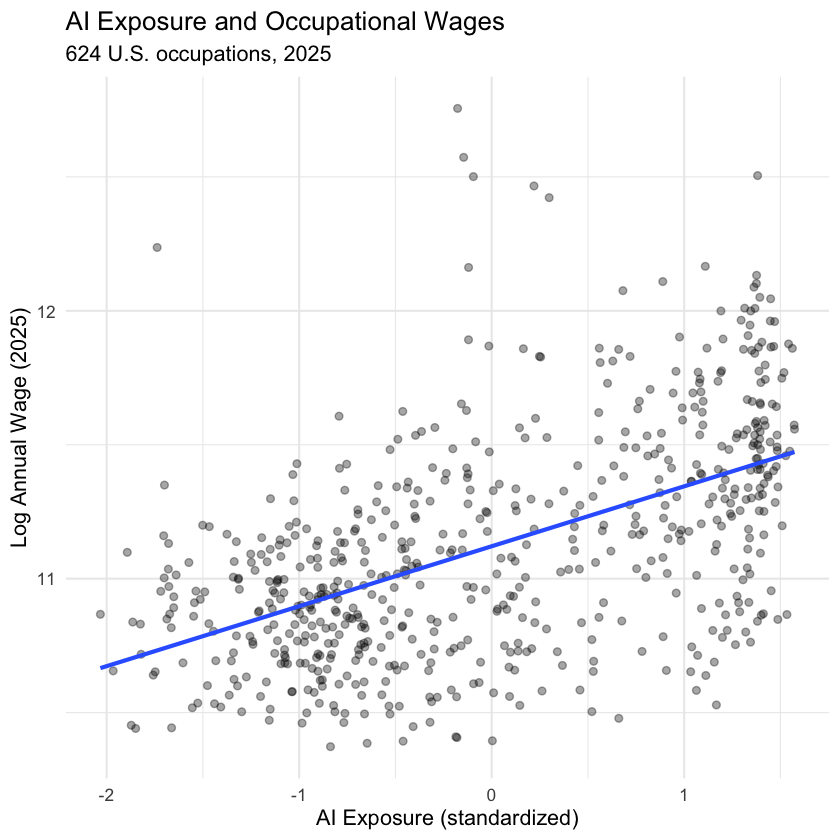

In [25]:
ggplot(analysis_data, aes(x = AI, y = log_wage)) +
  geom_point(alpha = 0.35) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE ) +
  labs(title = "AI Exposure and Occupational Wages",
    subtitle = sprintf("%d U.S. occupations, 2025", nrow(analysis_data)),
    x = "AI Exposure (standardized)",
    y = "Log Annual Wage (2025)" ) +
  theme_minimal(base_size = 13)

A one-standard-deviation increase in AI exposure is associated with about 25.1% higher annual wages in the baseline regression (β = 0.224, p < 0.001).

### Model 2 — Overall human skills

In [27]:
model2 <- lm(log_wage ~ AI + Skills, data = analysis_data)
model2


Call:
lm(formula = log_wage ~ AI + Skills, data = analysis_data)

Coefficients:
(Intercept)           AI       Skills  
   11.12097     -0.04048      0.34633  


The AI coefficient turns negative after controlling for overall skill requirements (β = −0.040, p = 0.034).

### Model 3 — Employment and occupation controls

In [30]:
model3 <- lm(
  log_wage ~ AI + Skills + log_employment + occupation_group,
  data = analysis_data)
model3


Call:
lm(formula = log_wage ~ AI + Skills + log_employment + occupation_group, 
    data = analysis_data)

Coefficients:
       (Intercept)                  AI              Skills      log_employment  
          11.69085             0.02424             0.26938            -0.02337  
occupation_group13  occupation_group15  occupation_group17  occupation_group19  
          -0.27495            -0.16326            -0.14265            -0.27055  
occupation_group21  occupation_group23  occupation_group25  occupation_group27  
          -0.70405            -0.33638            -0.36700            -0.28513  
occupation_group29  occupation_group31  occupation_group33  occupation_group35  
          -0.15518            -0.54866            -0.43619            -0.53935  
occupation_group37  occupation_group39  occupation_group41  occupation_group43  
          -0.38863            -0.55103            -0.41352            -0.51517  
occupation_group45  occupation_group47  occupation_group49  occupati

After adding log employment and broad occupation groups, the AI coefficient is small and statistically insignificant at 5% (β = 0.024, p = 0.399).

### Model 4 — Communication and problem-solving

In [31]:
model4 <- lm(
  log_wage ~ AI + Communication + ProblemSolving +
    log_employment + occupation_group,
  data = analysis_data
)
model4


Call:
lm(formula = log_wage ~ AI + Communication + ProblemSolving + 
    log_employment + occupation_group, data = analysis_data)

Coefficients:
       (Intercept)                  AI       Communication      ProblemSolving  
          11.62904             0.04689            -0.01476             0.26503  
    log_employment  occupation_group13  occupation_group15  occupation_group17  
          -0.01962            -0.24880            -0.28654            -0.18190  
occupation_group19  occupation_group21  occupation_group23  occupation_group25  
          -0.27086            -0.61438            -0.28645            -0.29464  
occupation_group27  occupation_group29  occupation_group31  occupation_group33  
          -0.23550            -0.11409            -0.46117            -0.39243  
occupation_group35  occupation_group37  occupation_group39  occupation_group41  
          -0.49085            -0.36894            -0.44893            -0.30432  
occupation_group43  occupation_group45  occu

Problem-solving has a positive wage association (β = 0.265, p < 0.001). The communication coefficient is close to zero (β = −0.015, p = 0.549). Section 5 tests the difference directly.

### Model 5 — AI exposure and skill interactions

In [33]:
model5 <- lm(log_wage ~ AI * Communication +
    AI * ProblemSolving +
    log_employment + occupation_group,
  data = analysis_data)
model5


Call:
lm(formula = log_wage ~ AI * Communication + AI * ProblemSolving + 
    log_employment + occupation_group, data = analysis_data)

Coefficients:
       (Intercept)                  AI       Communication      ProblemSolving  
         11.580735            0.050117           -0.004270            0.260288  
    log_employment  occupation_group13  occupation_group15  occupation_group17  
         -0.021034           -0.236314           -0.347915           -0.166204  
occupation_group19  occupation_group21  occupation_group23  occupation_group25  
         -0.268979           -0.603914           -0.312416           -0.282257  
occupation_group27  occupation_group29  occupation_group31  occupation_group33  
         -0.187865           -0.065841           -0.405838           -0.330037  
occupation_group35  occupation_group37  occupation_group39  occupation_group41  
         -0.460443           -0.346373           -0.402543           -0.253760  
occupation_group43  occupation_group45 

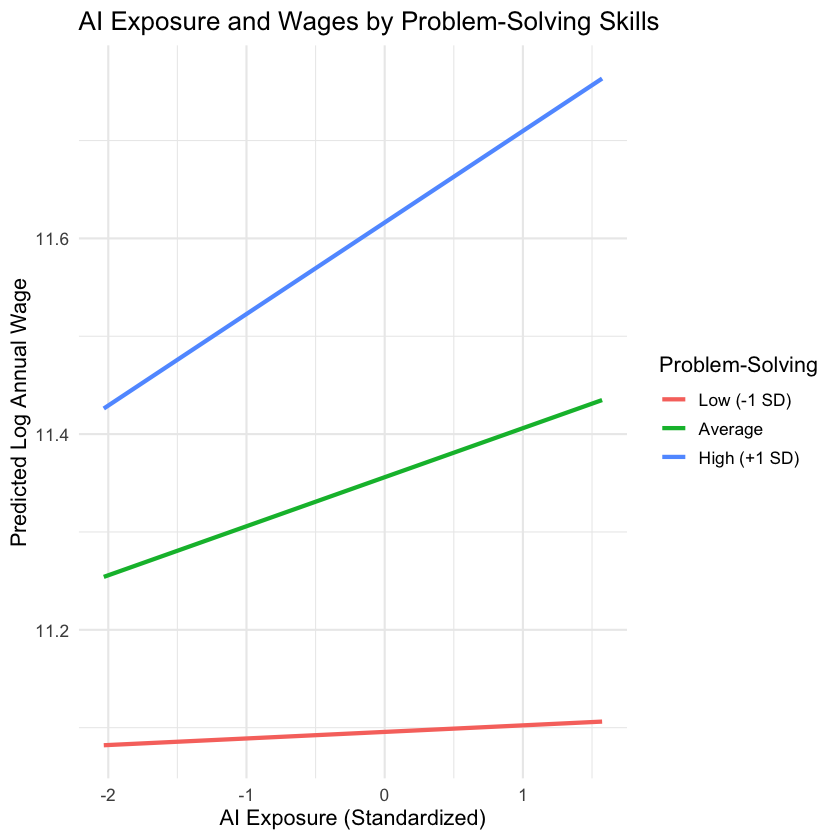

In [34]:
plot_data <- expand.grid(
  AI = seq(min(analysis_data$AI), max(analysis_data$AI),
           length.out = 100),
  ProblemSolving = c(-1, 0, 1),
  Communication = 0,
  log_employment = mean(analysis_data$log_employment),
  occupation_group = levels(analysis_data$occupation_group)[1])

plot_data$Predicted_Log_Wage <- predict(model5, newdata = plot_data)

plot_data$Skill_Level <- factor(
  plot_data$ProblemSolving,
  levels = c(-1, 0, 1),
  labels = c("Low (-1 SD)", "Average", "High (+1 SD)"))

ggplot(plot_data,
       aes(x = AI, y = Predicted_Log_Wage, color = Skill_Level)) +
  geom_line(linewidth = 1.2) +
  labs(title = "AI Exposure and Wages by Problem-Solving Skills",
    x = "AI Exposure (Standardized)",
    y = "Predicted Log Annual Wage",
    color = "Problem-Solving") +
  theme_minimal(base_size = 13)

The AI–wage slope is steeper in occupations with higher problem-solving requirements (interaction β = 0.043, p = 0.016). The AI × Communication interaction is small (β = −0.002, p = 0.922).

## 4. Robustness checks

### Model 6 — Nonlinear specification

In [35]:
model6 <- lm(
  log_wage ~ AI * Communication +
    AI * ProblemSolving +
    I(AI^2) +
    I(Communication^2) +
    I(ProblemSolving^2) +
    log_employment + occupation_group,
  data = analysis_data)
model6


Call:
lm(formula = log_wage ~ AI * Communication + AI * ProblemSolving + 
    I(AI^2) + I(Communication^2) + I(ProblemSolving^2) + log_employment + 
    occupation_group, data = analysis_data)

Coefficients:
        (Intercept)                   AI        Communication  
          11.520760             0.048395            -0.012741  
     ProblemSolving              I(AI^2)   I(Communication^2)  
           0.271152             0.054212             0.008438  
I(ProblemSolving^2)       log_employment   occupation_group13  
           0.043552            -0.020111            -0.234620  
 occupation_group15   occupation_group17   occupation_group19  
          -0.413349            -0.166871            -0.264927  
 occupation_group21   occupation_group23   occupation_group25  
          -0.579036            -0.342652            -0.258473  
 occupation_group27   occupation_group29   occupation_group31  
          -0.177646            -0.070506            -0.381118  
 occupation_group33   o

Adding squared terms allows the associations to curve. The AI × Problem-solving interaction is statistically insignificant (p = 0.679).

### Model 7 — Employment weighting

In [36]:
model7 <- lm(
  log_wage ~ AI * Communication +
    AI * ProblemSolving +
    log_employment + occupation_group,
  data = analysis_data,
  weights = exp(log_employment))
model7


Call:
lm(formula = log_wage ~ AI * Communication + AI * ProblemSolving + 
    log_employment + occupation_group, data = analysis_data, 
    weights = exp(log_employment))

Coefficients:
       (Intercept)                  AI       Communication      ProblemSolving  
          11.64759             0.07993            -0.02295             0.28544  
    log_employment  occupation_group13  occupation_group15  occupation_group17  
          -0.01771            -0.42648            -0.61141            -0.24064  
occupation_group19  occupation_group21  occupation_group23  occupation_group25  
          -0.41387            -0.80582            -0.22250            -0.54297  
occupation_group27  occupation_group29  occupation_group31  occupation_group33  
          -0.43603            -0.28009            -0.50819            -0.40464  
occupation_group35  occupation_group37  occupation_group39  occupation_group41  
          -0.51821            -0.32840            -0.61020            -0.50531  
occ

Weighting by employment gives larger occupations more influence. The AI × Problem-solving interaction remains statistically insignificant (p = 0.635). The interaction finding from Model 5 is sensitive to the specification.

## 5. Regression results with HC1 robust inference

HC1 is a way to calculate standard errors 
Standard errors accounts for uneven residual spread across occupations.

HC1 adjusts the standard errors to account for the possibility that wage predictions are more spread out for some occupations than others. The estimated coefficients stay the same, but the p-values can change.

In [51]:
hc1_covariance <- function(model) {
  X <- model.matrix(model)
  e <- residuals(model)
  w <- weights(model)
  if (is.null(w)) w <- rep(1, nrow(X))

  Xw <- X * sqrt(w)
  ew <- e * sqrt(w)
  bread <- solve(crossprod(Xw))
  scores <- Xw * ew
  (nobs(model) / df.residual(model)) * bread %*% crossprod(scores) %*% bread
}

In [52]:
models <- list(model1, model2, model3, model4, model5, model6, model7)
focal_terms <- c("AI", "Skills", "Communication", "ProblemSolving",
                 "AI:Communication", "AI:ProblemSolving")

final_table <- bind_rows(lapply(seq_along(models), function(i) {
  model <- models[[i]]
  estimates <- coef(model)
  terms <- intersect(focal_terms, names(estimates))
  se <- sqrt(diag(hc1_covariance(model)))[terms]
  data.frame(Model = paste("Model", i), Variable = terms,
             Estimate = unname(estimates[terms]), Robust_SE = unname(se),
             p_value = unname(2 * pt(-abs(estimates[terms] / se),
                                     df = df.residual(model))))
}))

print(final_table %>%
        mutate(across(c(Estimate, Robust_SE), function(x) round(x, 4)),
               p_value = signif(p_value, 3)),
      row.names = FALSE)

   Model          Variable Estimate Robust_SE  p_value
 Model 1                AI   0.2238    0.0132 2.98e-53
 Model 2                AI  -0.0405    0.0191 3.41e-02
 Model 2            Skills   0.3463    0.0209 2.65e-51
 Model 3                AI   0.0242    0.0287 3.99e-01
 Model 3            Skills   0.2694    0.0241 1.78e-26
 Model 4                AI   0.0469    0.0294 1.11e-01
 Model 4     Communication  -0.0148    0.0246 5.49e-01
 Model 4    ProblemSolving   0.2650    0.0231 1.12e-27
 Model 5                AI   0.0501    0.0291 8.60e-02
 Model 5     Communication  -0.0043    0.0248 8.63e-01
 Model 5    ProblemSolving   0.2603    0.0234 2.85e-26
 Model 5  AI:Communication  -0.0018    0.0181 9.22e-01
 Model 5 AI:ProblemSolving   0.0434    0.0180 1.60e-02
 Model 6                AI   0.0484    0.0266 6.89e-02
 Model 6     Communication  -0.0127    0.0235 5.88e-01
 Model 6    ProblemSolving   0.2712    0.0249 2.29e-25
 Model 6  AI:Communication  -0.0338    0.0421 4.22e-01
 Model 6 A

### Model 4 coefficient equality test

Both skill indices are standardized. Test whether their wage coefficients are equal, using the HC1 covariance between the two estimates to calculate the standard error of their difference.

In [53]:
contrast <- c(ProblemSolving = 1, Communication = -1)
terms <- names(contrast)
difference <- sum(contrast * coef(model4)[terms])
V <- hc1_covariance(model4)[terms, terms]
robust_se <- sqrt(drop(crossprod(contrast, V %*% contrast)))
t_statistic <- difference / robust_se
p_value <- 2 * pt(-abs(t_statistic), df = df.residual(model4))

data.frame(Difference = difference, Robust_SE = robust_se,
           t_statistic = t_statistic, p_value = p_value)

Difference,Robust_SE,t_statistic,p_value
<dbl>,<dbl>,<dbl>,<dbl>
0.2797879,0.04037339,6.930007,1.092236e-11


The estimated problem-solving coefficient exceeds the communication coefficient by about 0.280 log points per standard deviation. The HC1 test rejects equality (t = 6.93, p < 0.001).

## 7. How we test our results

### A. HC1 standard errors
Because the size of those mistakes can vary, we used HC1 to account for that when measuring the uncertainty of our estimates. This keeps the estimated relationships the same and can change their p-values.

### B. Residuals versus fitted values
We compared the wages Model 5 predicted with the wages we observed. The plot helps me see whether the model tends to make bigger mistakes at some wage levels than others.

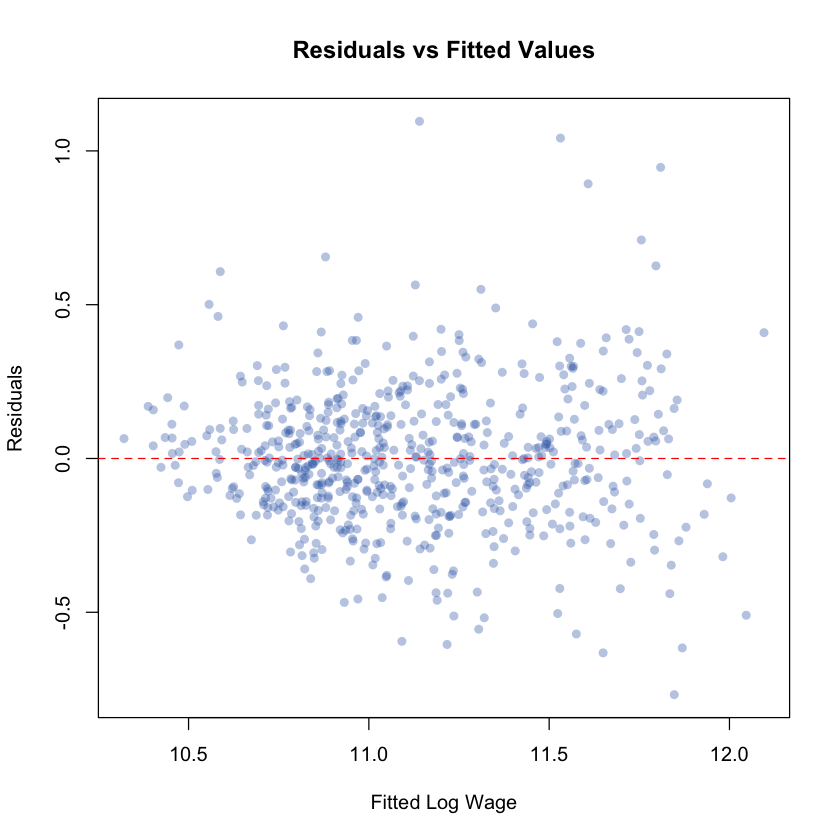

In [55]:
plot(fitted(model5),
  resid(model5),
  pch = 16,
  col = rgb(0.2, 0.4, 0.7, 0.35),
  xlab = "Fitted Log Wage",
  ylab = "Residuals",
  main = "Residuals vs Fitted Values"
)

abline(h = 0, col = "red", lty = 2)

### C. Model fit

Adjusted R² tells us how much of the variation in log wages the model explains, while accounting for how many predictors it uses. In Models 1–6, each occupation counts equally. In Model 7, occupations with more workers count more, so its adjusted R² reflects how well the model fits when larger occupations get more weight.

In [56]:
comparison <- data.frame(
  Model = paste0("Model ", 1:7),
  AI_Coefficient = sapply(models, function(m) coef(m)["AI"]),
  Adjusted_R2 = sapply(models, function(m) summary(m)$adj.r.squared)
)

comparison

Model,AI_Coefficient,Adjusted_R2
<chr>,<dbl>,<dbl>
Model 1,0.22378479,0.2838016
Model 2,-0.04048467,0.5686786
Model 3,0.02423725,0.6804489
Model 4,0.04688799,0.6972396
Model 5,0.05011723,0.7021820
Model 6,0.04839460,0.7094923
Model 7,0.07992916,0.8563333


### D. Additional descriptive statistics

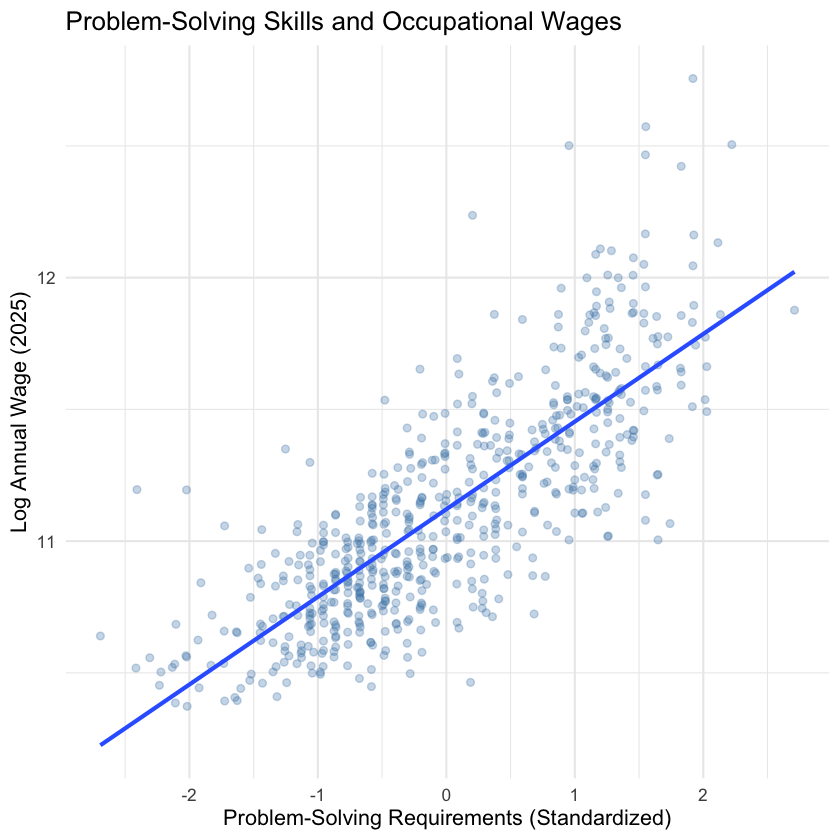

In [57]:
ggplot(analysis_data, aes(x = ProblemSolving, y = log_wage)) +
  geom_point(alpha = 0.3, color = "steelblue")  +
geom_smooth(method = "lm", formula = y ~ x, se = FALSE)+
  labs(title = "Problem-Solving Skills and Occupational Wages",
    x = "Problem-Solving Requirements (Standardized)",
    y = "Log Annual Wage (2025)") +
  theme_minimal(base_size = 13)

In [58]:
describe(list(
  "AI exposure squared" = analysis_data$AI^2,
  "Human skills squared" = analysis_data$Skills^2,
  "Communication squared" = analysis_data$Communication^2,
  "Problem-solving squared" = analysis_data$ProblemSolving^2,
  "AI × Skills" = with(analysis_data, AI * Skills),
  "AI × Communication" = with(analysis_data, AI * Communication),
  "AI × Problem-solving" = with(analysis_data, AI * ProblemSolving)
))

occupation_counts <- as.data.frame(table(analysis_data$occupation_group))
names(occupation_counts) <- c("SOC_group", "Occupations")
occupation_counts$Share <- occupation_counts$Occupations / nrow(analysis_data)
occupation_counts

Variable,N,Mean,SD,Min,Max
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
AI exposure squared,624,0.9983974,0.8292842,1.339988e-05,4.131231
Human skills squared,624,0.9983974,1.0157787,3.847171e-06,7.367165
Communication squared,624,0.9983974,0.9097031,6.298762e-05,9.319532
Problem-solving squared,624,0.9983974,1.1454501,9.875581e-06,7.344743
AI × Skills,624,0.7618283,0.8583504,-1.607115e+00,5.081541
AI × Communication,624,0.8023085,0.8102173,-1.535453e+00,5.715343
AI × Problem-solving,624,0.6640904,0.9089879,-2.138536e+00,4.733681


SOC_group,Occupations,Share
<fct>,<int>,<dbl>
11,26,0.041666667
13,21,0.033653846
15,3,0.004807692
17,24,0.038461538
19,32,0.051282051
21,12,0.019230769
23,7,0.011217949
25,52,0.083333333
27,29,0.046474359


## Conclusion for Question 1

- Baseline: Across 624 U.S. occupations, one standard deviation higher AI exposure was associated with about 25% higher wages.

- After controls: The estimate fell to about 2.5% and was statistically insignificant (p = 0.399). It was significant in the employment-weighted model at average skill levels (p = 0.014).

- Skills: Problem-solving had a stronger wage association than communication (p < 0.001).

- Interaction: The AI–wage association was stronger in occupations requiring more problem-solving in Model 5 (p = 0.016). This result did not hold in either robustness check.

- Conclusion: The results show associations across occupations. A causal effect of AI exposure on wages remains uninformative.


## Exploratory comparison of 2019 and 2025

This section compares mean annual wages for occupations with usable wages in both years. It converts May 2019 wages to May 2025 dollars using the U.S. CPI-U series `CPIAUCNS`. The comparison is descriptive. A regression testing whether the AI–wage association changed between years remains future work.

In [62]:
historical_files <- file.path(data_dir, c(
  "oesm19nat/national_M2019_dl.xlsx", "CPIAUCNS.csv"
))

if (all(file.exists(historical_files))) {
  bls_2019 <- read_excel(historical_files[1]) %>%
    filter(area == "99", naics == "000000", own_code == "1235",
           o_group == "detailed") %>%
    transmute(soc = occ_code, occupation_2019 = occ_title,
              wage_2019 = suppressWarnings(as.numeric(a_mean)),
              employment_2019 = suppressWarnings(as.numeric(tot_emp)))
  stopifnot(!anyDuplicated(bls_2019$soc))

  cpi_raw <- read.csv(historical_files[2])
  cpi_dates <- c("2019-05-01", "2025-05-01")
  cpi_selected <- cpi_raw[cpi_raw$observation_date %in% cpi_dates, ]
  cpi <- cpi_selected$CPIAUCNS[match(cpi_dates, cpi_selected$observation_date)]
  if (nrow(cpi_selected) != 2 || !is.numeric(cpi) ||
      any(!is.finite(cpi) | cpi <= 0)) {
    stop("CPIAUCNS.csv must contain one positive CPI value for each May date.")
  }

  comparison_data <- left_join(analysis_data, bls_2019, by = "soc") %>%
    mutate(real_wage_2019 = wage_2019 * cpi[2] / cpi[1],
           real_wage_2025 = wage)

  matched_wages <- comparison_data %>%
    filter(is.finite(real_wage_2019), real_wage_2019 > 0)
  print(data.frame(occupations_2025 = nrow(comparison_data),
                   matched_wages = nrow(matched_wages)))
  if (nrow(matched_wages) > 0) {
    wage_comparison_table <- describe(list(
      "2019 annual wage in 2025 dollars" = matched_wages$real_wage_2019,
      "2025 annual wage" = matched_wages$real_wage_2025
    ))
    print(wage_comparison_table, row.names = FALSE)
  }
} else {
  message("Skipping the exploratory comparison. Missing: ",
          paste(historical_files[!file.exists(historical_files)], collapse = ", "))
}

  occupations_2025 matched_wages
1              624           624
                         Variable   N     Mean       SD      Min      Max
 2019 annual wage in 2025 dollars 624 75856.14 38904.58 28758.27 298214.9
                 2025 annual wage 624 74421.17 37793.98 31980.00 346490.0


## E. Preparing the 2019 data for comparison

We kept occupations with usable 2019 wage and employment figures. We put 2019 wages in 2025 dollars so we could compare them after accounting for inflation. 

Then we took the logs of 2019 wages and employment and calculated how employment changed between 2019 and 2025.

The table summarizes these variables for a future analysis of how the relationship between AI exposure and wages may have changed.

In [63]:
if (all(file.exists(historical_files))) {
  historical_variables <- comparison_data %>%
    filter(real_wage_2019 > 0, employment_2019 > 0) %>%
    mutate(log_real_wage_2019 = log(real_wage_2019),
           log_employment_2019 = log(employment_2019),
           employment_log_change = 100 * (log_employment - log_employment_2019))
  if (nrow(historical_variables) > 0) {
    describe(list(
      "2019 log real wage (2025 dollars)" = historical_variables$log_real_wage_2019,
      "2019 log employment" = historical_variables$log_employment_2019,
      "2019–2025 employment log change (×100)" = historical_variables$employment_log_change
    ))
  }
}

Variable,N,Mean,SD,Min,Max
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
2019 log real wage (2025 dollars),624,11.129714,0.4485313,10.266681,12.60557
2019 log employment,624,10.735980,1.6243776,5.075174,15.27829
2019–2025 employment log change (×100),624,-4.959948,27.0527571,-117.418572,104.00726
